# 08 · Attention versus FFN routing

A controlled extension of the original switching-dynamics experiment. Full study: 13 model families, three paired seeds, unchanged data and 40 epochs. Smoke execution checks mechanics only.

## Setup

Run cells in order. Default: smoke. Set `TWILIGHT_CONFIG=configs/attention_experiment.yaml` for the full preset.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'twilight_moe').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from twilight_moe.config import load_config, run_dir
from twilight_moe.experiment import load_metrics, load_diagnostics, verify_provenance
from twilight_moe.attention import ATTENTION_NAMES
from twilight_moe.plotting import style, save_figure, COLORS
config_path = os.environ.get('TWILIGHT_CONFIG', 'configs/attention_smoke.yaml')
cfg = load_config(config_path)
if 'attention' not in cfg:
    cfg = load_config('configs/attention_smoke.yaml')
style()
print('Preset:', cfg['name'], '| seeds:', cfg['seeds'], '| epochs:', cfg['training']['epochs'])
print('Data:', cfg['data_root'])

Preset: attention_comparison_v1 | seeds: [7, 17, 27] | epochs: 40
Data: E:/HarunoKen/Twilight_MoE_Dynamics


## Context and references

[MoH: Multi-Head Attention as Mixture-of-Head Attention](https://proceedings.mlr.press/v267/jin25l.html) (Jin et al., ICML 2025) routes tokens between shared and selected heads. [Mixture of Attention Heads: Selecting Attention Heads Per Token](https://aclanthology.org/2022.emnlp-main.278/) (Zhang et al., EMNLP 2022) is an earlier token-level head-routing design. Our experiment implements a small MoH-inspired predictor, not either paper’s benchmark reproduction. See `docs/ATTENTION_EXPERIMENT.md` for exact mechanisms and deviations.

## Data and design

Same 4-D process, split sequences, training-only normalization and 8-state history. Regime labels enter only the original oracle and post-hoc diagnostics.

In [2]:
display(pd.Series(cfg['data'], name='Data setting').to_frame())
display(pd.Series(cfg['attention'], name='Attention setting').to_frame())

,Data setting
train_sequences,256.00
val_sequences,64.00
test_sequences,64.00
length,192.00
context,8.00
burn_in,128.00
noise_std,0.08
stay_probability,0.95


,Attention setting
width,16
layers,2
heads,4
head_dim,4
shared_heads,1
top_k,2
ffn_hidden,32
ffn_experts,3
ffn_top_k,2


## Architecture and capacities

Two causal pre-norm blocks, token embedding plus learned positions, and final-token readout. MoH uses one shared head and top-2 of three routed heads. Attention computations remain dense in this reference. Active parameter proxies do not mean FLOPs.

In [3]:
from twilight_moe.models import build_model
capacities = pd.DataFrame([{'model': n, **build_model(n, cfg).capacity()} for n in cfg['models']])
display(capacities.fillna('—'))
print(build_model('attn_moh', cfg))

,model,total_parameters,trainable_parameters,active_parameters,attention_heads,logical_selected_heads,attention_dense_compute
0,dense_active,5419,5419,5419,—,—,—
1,dense_total,7564,7564,7564,—,—,—
2,moe,7599,7599,5355,—,—,—
3,random,6828,6732,4584,—,—,—
4,oracle,6732,6732,2244,—,—,—
5,attn_dense,4628,4628,4628,4.0,4.0,True
6,attn_active,4116,4116,4116,3.0,3.0,True
7,attn_total,4826,4826,4826,4.0,4.0,True
8,attn_moh,4820,4820,4820,4.0,3.0,True
9,attn_random,4820,4628,4820,4.0,3.0,True


AttentionPredictor(
  (embedding): Linear(in_features=4, out_features=16, bias=True)
  (blocks): ModuleList(
    (0-1): 2 x TransformerBlock(
      (norm_attention): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
      (attention): HeadAttention(
        (qkv): Linear(in_features=16, out_features=48, bias=False)
        (output): Linear(in_features=16, out_features=16, bias=False)
        (route_gate): Linear(in_features=16, out_features=3, bias=False)
        (type_gate): Linear(in_features=16, out_features=2, bias=False)
        (shared_gate): Linear(in_features=16, out_features=1, bias=False)
      )
      (norm_ffn): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
      (ffn): TokenFFN(
        (experts): ModuleList(
          (0): Sequential(
            (0): Linear(in_features=16, out_features=32, bias=True)
            (1): GELU(approximate='none')
            (2): Linear(in_features=32, out_features=16, bias=True)
          )
        )
      )
 

## Train or validate a complete saved run

This cell reuses only complete runs whose per-family and manifest source hashes match. Set FORCE_RETRAIN=True to train all families again. Original MLP baselines rerun in the same experiment namespace.

In [4]:
from twilight_moe.experiment import run_models
FORCE_RETRAIN = False
try:
    valid_cache = verify_provenance(cfg)
except (FileNotFoundError, ValueError, KeyError):
    valid_cache = False
if FORCE_RETRAIN or not valid_cache:
    run_models(cfg)
assert verify_provenance(cfg)
results = load_metrics(cfg)
display(results[['model','seed','best_epoch','test_mse','training_seconds']].round(6))

,model,seed,best_epoch,test_mse,training_seconds
0,dense_active,7,39,0.011182,13.396431
1,dense_total,7,37,0.011116,13.552360
2,moe,7,37,0.011591,17.756192
3,random,7,40,0.011750,16.227475
4,oracle,7,39,0.006621,15.368037
5,attn_dense,7,39,0.011026,52.892871
6,attn_active,7,39,0.011037,48.664258
7,attn_total,7,39,0.010722,54.709819
8,attn_moh,7,39,0.010897,65.706938
9,attn_random,7,39,0.010910,62.635154


## Validation trajectories

First seed only. Pure validation prediction MSE determines checkpoints. All models use the same minibatch order for each seed.

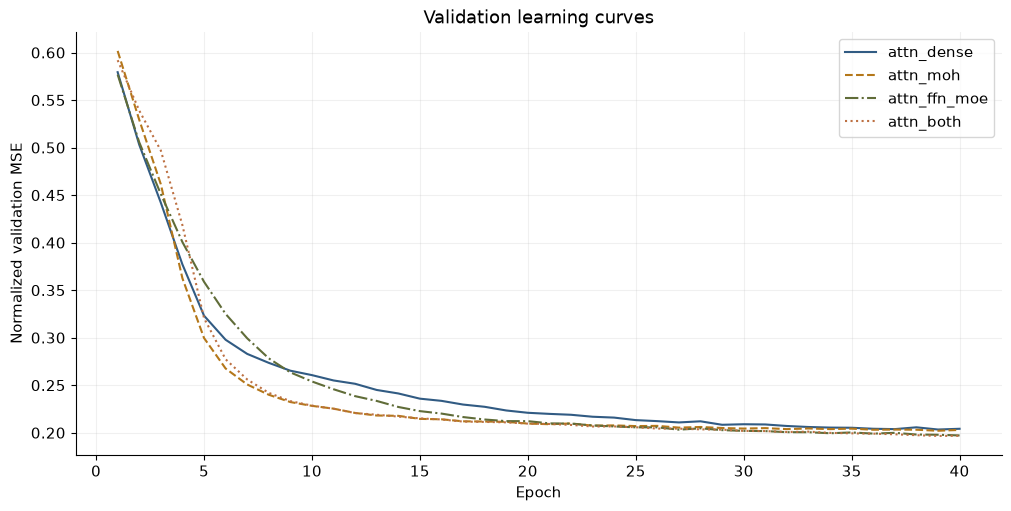

In [5]:
selected = ['attn_dense','attn_moh','attn_ffn_moe','attn_both']
fig, ax = plt.subplots(figsize=(10, 5))
for i, name in enumerate(selected):
    history = pd.read_csv(run_dir(cfg)/f"{name}_seed{cfg['seeds'][0]}_history.csv")
    ax.plot(history.epoch, history.val_mse_normalized, color=COLORS[name],
            linestyle=['-','--','-.',':'][i], label=name)
ax.set(xlabel='Epoch', ylabel='Normalized validation MSE', title='Validation learning curves')
ax.legend()
save_figure(fig, cfg, 'attention_learning_curves')
plt.show()